# Лабораторная работа. Обучение без учителя: кластеризация и понижение размерности

**Курс:** Технологии машинного обучения

**Цель работы:** изучение методов кластеризации и понижения размерности.

**Задание:**
1. Выбрать набор данных для решения задачи обучения без учителя.
2. Выбрать подмножество признаков (больше двух, целевой признак исключить) — набор **D1**.
3. Понизить размерность D1 до двух методом PCA — набор **D2**.
4. Понизить размерность D1 до двух методом t-SNE — набор **D3**.
5. Визуализировать точки D2 и D3; определить, на каком наборе кластеры видны лучше.
6. Выполнить кластеризацию D1, D2 и D3 не менее чем тремя методами из лекционного ноутбука и оценить качество метриками из него.
7. Сделать выводы о том, какой метод кластеризации лучше на каждом наборе и почему.

Ссылка на постановку задания: https://github.com/ugapanyuk/courses_current/wiki/LAB_TMO_CLUSTER

## 1. Выбор набора данных

Используется датасет **Wine** с платформы Kaggle
([tawfikelmetwally/wine-dataset](https://www.kaggle.com/datasets/tawfikelmetwally/wine-dataset)):
химический анализ 178 образцов вина трёх сортов (`class` = 1, 2, 3), 13 числовых признаков. Файл сохранён в `data/wine.csv`.

Метка `class` **не используется при кластеризации и понижении размерности**. Она нужна только для оценки: по ней
считаются внешние метрики (ARI, AMI, гомогенность, полнота, V-мера) и раскрашиваются точки на графиках.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, adjusted_rand_score, adjusted_mutual_info_score,
                             homogeneity_completeness_v_measure)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

## 2. Загрузка данных и выбор признаков (набор D1)

In [2]:
data = pd.read_csv("data/wine.csv")
data.columns = [c.strip() for c in data.columns]     # в исходном файле у 'Proline' есть пробел в конце

print("Размер:", data.shape, "| пропусков:", int(data.isna().sum().sum()))
print("Число образцов по сортам:", data["class"].value_counts().sort_index().to_dict())
data.head()

Размер: (178, 14) | пропусков: 0
Число образцов по сортам: {1: 59, 2: 71, 3: 48}


,class,Alcohol,Malic acid,Ash,Alcalinity of ash,Magnesium,Total phenols,Flavanoids,Nonflavanoid phenols,Proanthocyanins,Color intensity,Hue,OD280/OD315 of diluted wines,Proline
0,1,14.23,1.71,2.43,15.6,127,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065
1,1,13.20,1.78,2.14,11.2,100,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050
2,1,13.16,2.36,2.67,18.6,101,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185
3,1,14.37,1.95,2.50,16.8,113,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480
4,1,13.24,2.59,2.87,21.0,118,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735


Выбрано признаков: 12 из 13
Исключены: ['Flavanoids']


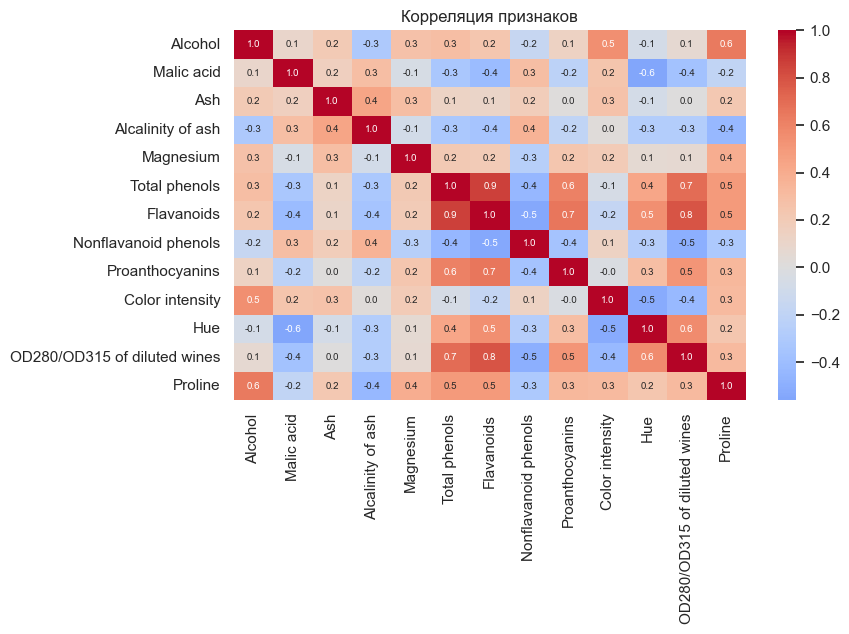

In [3]:
y = data["class"].values
features = data.drop(columns="class")

# Признаки выбираются без использования метки: если два признака сильно коррелируют (|r| > 0.7),
# оставляем первый из них.
corr = features.corr().abs()
selected = []
for col in features.columns:
    if all(corr.loc[col, kept] <= 0.7 for kept in selected):
        selected.append(col)
dropped = [c for c in features.columns if c not in selected]
print("Выбрано признаков:", len(selected), "из", features.shape[1])
print("Исключены:", dropped)

plt.figure(figsize=(9, 6.5))
sns.heatmap(features.corr(), cmap="coolwarm", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Корреляция признаков")
plt.tight_layout()
plt.show()

In [4]:
# D1: выбранные признаки, приведённые к одному масштабу (признаки в разных единицах: Proline ~ 10^3, Hue ~ 1)
D1 = StandardScaler().fit_transform(features[selected])
print("D1:", D1.shape)

D1: (178, 12)


## 3. Понижение размерности: PCA (набор D2)

In [5]:
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(D1)
D2 = pca.transform(D1)
print("Доля объяснённой дисперсии:", pca.explained_variance_ratio_.round(3),
      "| суммарно:", round(pca.explained_variance_ratio_.sum(), 3))

Доля объяснённой дисперсии: [0.325 0.208] | суммарно: 0.533


## 4. Понижение размерности: t-SNE (набор D3)

In [6]:
D3 = TSNE(n_components=2, perplexity=30, init="pca", random_state=RANDOM_STATE).fit_transform(D1)
print("D3:", D3.shape)

D3: (178, 2)


## 5. Визуализация D2 и D3

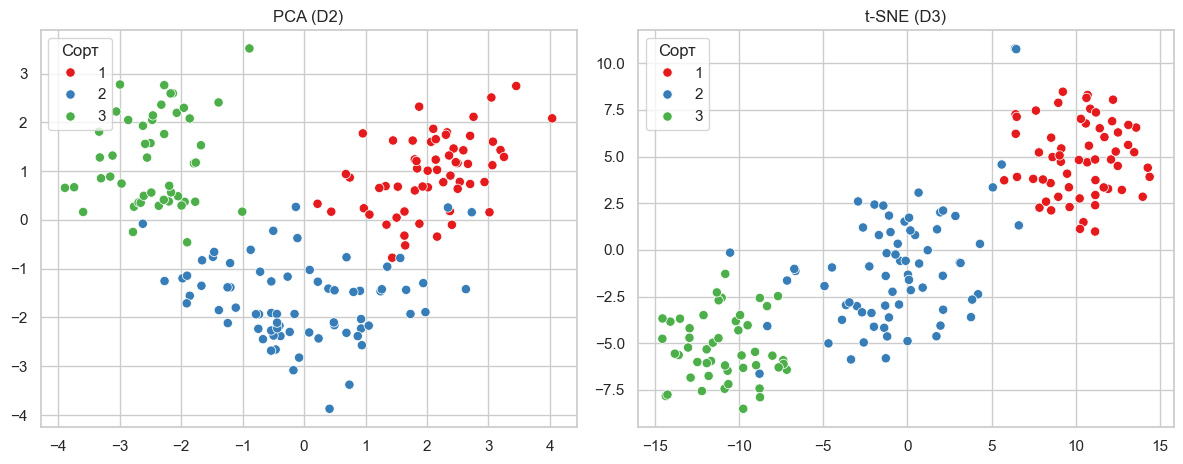

Силуэт по истинным сортам, D1         : 0.271
Силуэт по истинным сортам, D2 (PCA)   : 0.522
Силуэт по истинным сортам, D3 (t-SNE) : 0.550


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
for ax, D, title in zip(axes, (D2, D3), ("PCA (D2)", "t-SNE (D3)")):
    sns.scatterplot(x=D[:, 0], y=D[:, 1], hue=y, palette="Set1", s=45, ax=ax)
    ax.set_title(title)
    ax.legend(title="Сорт")
plt.tight_layout()
plt.show()

# Количественная оценка «чёткости» кластеров: силуэт по истинным меткам (чем выше, тем лучше разделены сорта)
for name, D in (("D1", D1), ("D2 (PCA)", D2), ("D3 (t-SNE)", D3)):
    print(f"Силуэт по истинным сортам, {name:<11}: {silhouette_score(D, y):.3f}")

**Ответ на вопрос задания.** Силуэт по истинным сортам выше у t-SNE (D3 = 0.550), чем у PCA (D2 = 0.522), и оба заметно выше,
чем в исходном 12-мерном пространстве (D1 = 0.271). То есть оба метода делают структуру из трёх сортов видимой, а **t-SNE показывает кластеры
чуть чётче**; разница небольшая. Нужно учитывать, что t-SNE сохраняет соседство точек, но не расстояния между кластерами и их размеры,
поэтому судить по нему о «расстоянии» между сортами нельзя. Две компоненты PCA объясняют только 53 % дисперсии.

## 6. Кластеризация D1, D2 и D3

Используются четыре метода из лекционного ноутбука: **K-Means**, **иерархическая (Agglomerative, Ward)**, **DBSCAN**
и **смесь гауссиан (GMM)**. Метрики из лекции:
- внутренняя: **силуэт** (silhouette) — считается по самим данным, метки не нужны;
- внешние (сравнение с истинными сортами): **ARI**, **AMI**, **гомогенность**, **полнота**, **V-мера**.

Число кластеров для K-Means, Agglomerative и GMM выбирается без меток — по максимуму силуэта K-Means.

In [8]:
rows = []
for k in range(2, 8):
    row = {"k": k}
    for name, D in (("D1", D1), ("D2", D2), ("D3", D3)):
        row[name] = silhouette_score(D, KMeans(k, n_init=10, random_state=RANDOM_STATE).fit_predict(D))
    rows.append(row)
sil_k = pd.DataFrame(rows).set_index("k").round(3)
display(sil_k)
print("k с максимальным силуэтом:", sil_k.idxmax().to_dict())

,D1,D2,D3
k,,,
2,0.245,0.448,0.586
3,0.277,0.553,0.616
4,0.241,0.475,0.513
5,0.201,0.435,0.416
6,0.165,0.427,0.359
7,0.201,0.405,0.374


k с максимальным силуэтом: {'D1': 3, 'D2': 3, 'D3': 3}


In [9]:
K = 3     # максимум силуэта K-Means на всех трёх наборах (см. таблицу выше); совпадает с числом сортов
spaces = {"D1": D1, "D2 (PCA)": D2, "D3 (t-SNE)": D3}

def dbscan_auto(D, min_samples=5):
    # eps подбирается без меток: максимум силуэта среди вариантов, где найдено >= 2 кластеров
    # и в шум попало не больше половины точек
    best = None
    for eps in np.arange(0.2, 3.01, 0.1):
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(D)
        mask = labels != -1
        if len(set(labels[mask])) >= 2 and mask.mean() > 0.5:
            s = silhouette_score(D[mask], labels[mask])
            if best is None or s > best[0]:
                best = (s, eps, labels)
    return best[2], round(best[1], 1)

def cluster_all(D):
    out = {}
    out["K-Means"] = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit_predict(D)
    out["Agglomerative"] = AgglomerativeClustering(K, linkage="ward").fit_predict(D)
    out["DBSCAN"], eps = dbscan_auto(D)
    out["GMM"] = GaussianMixture(K, n_init=5, random_state=RANDOM_STATE).fit_predict(D)
    return out, eps

def quality(D, labels):
    noise = labels == -1                       # DBSCAN: -1 = шум; силуэт считаем только по кластеризованным точкам
    sil = silhouette_score(D[~noise], labels[~noise]) if len(set(labels[~noise])) > 1 else np.nan
    h, c, v = homogeneity_completeness_v_measure(y, labels)    # шум считается отдельной группой
    return {"Кластеров": len(set(labels)) - int(noise.any()), "Шум, точек": int(noise.sum()), "Силуэт": sil,
            "ARI": adjusted_rand_score(y, labels), "AMI": adjusted_mutual_info_score(y, labels),
            "Гомогенность": h, "Полнота": c, "V-мера": v}

labels_all, rows, eps_used = {}, [], {}
for sname, D in spaces.items():
    labels_all[sname], eps_used[sname] = cluster_all(D)
    for mname, labels in labels_all[sname].items():
        rows.append({"Набор": sname, "Метод": mname, **quality(D, labels)})
results = pd.DataFrame(rows).set_index(["Набор", "Метод"])
print("eps для DBSCAN:", eps_used)
results.round(3)

eps для DBSCAN: {'D1': np.float64(2.2), 'D2 (PCA)': np.float64(0.4), 'D3 (t-SNE)': np.float64(1.1)}


Кластеров  Шум, точек  Силуэт    ARI    AMI  \
Набор      Метод                                                        
D1         K-Means                3           0   0.277  0.880  0.859   
           Agglomerative          3           0   0.260  0.714  0.699   
           DBSCAN                 2          52   0.320  0.343  0.427   
           GMM                    3           0   0.277  0.880  0.859   
D2 (PCA)   K-Means                3           0   0.553  0.895  0.881   
           Agglomerative          3           0   0.524  0.711  0.708   
           DBSCAN                 7          74   0.609  0.228  0.437   
           GMM                    3           0   0.549  0.898  0.864   
D3 (t-SNE) K-Means                3           0   0.616  0.802  0.793   
           Agglomerative          3           0   0.607  0.774  0.772   
           DBSCAN                 3          69   0.734  0.404  0.541   
           GMM                    3           0   0.616  0.802  0.793   

                          Гомогенность  Полнота  V-мера  
Набор      Метод                                         
D1         K-Means               0.864    0.858   0.861  
           Agglomerative         0.706    0.699   0.702  
           DBSCAN                0.422    0.444   0.433  
           GMM                   0.864    0.858   0.861  
D2 (PCA)   K-Means               0.884    0.880   0.882  
           Agglomerative         0.710    0.711   0.711  
           DBSCAN                0.587    0.370   0.454  
           GMM                   0.866    0.866   0.866  
D3 (t-SNE) K-Means               0.799    0.792   0.795  
           Agglomerative         0.778    0.770   0.774  
           DBSCAN                0.609    0.496   0.547  
           GMM                   0.799    0.792   0.795

### Визуализация результатов кластеризации (на плоскостях D2 и D3)

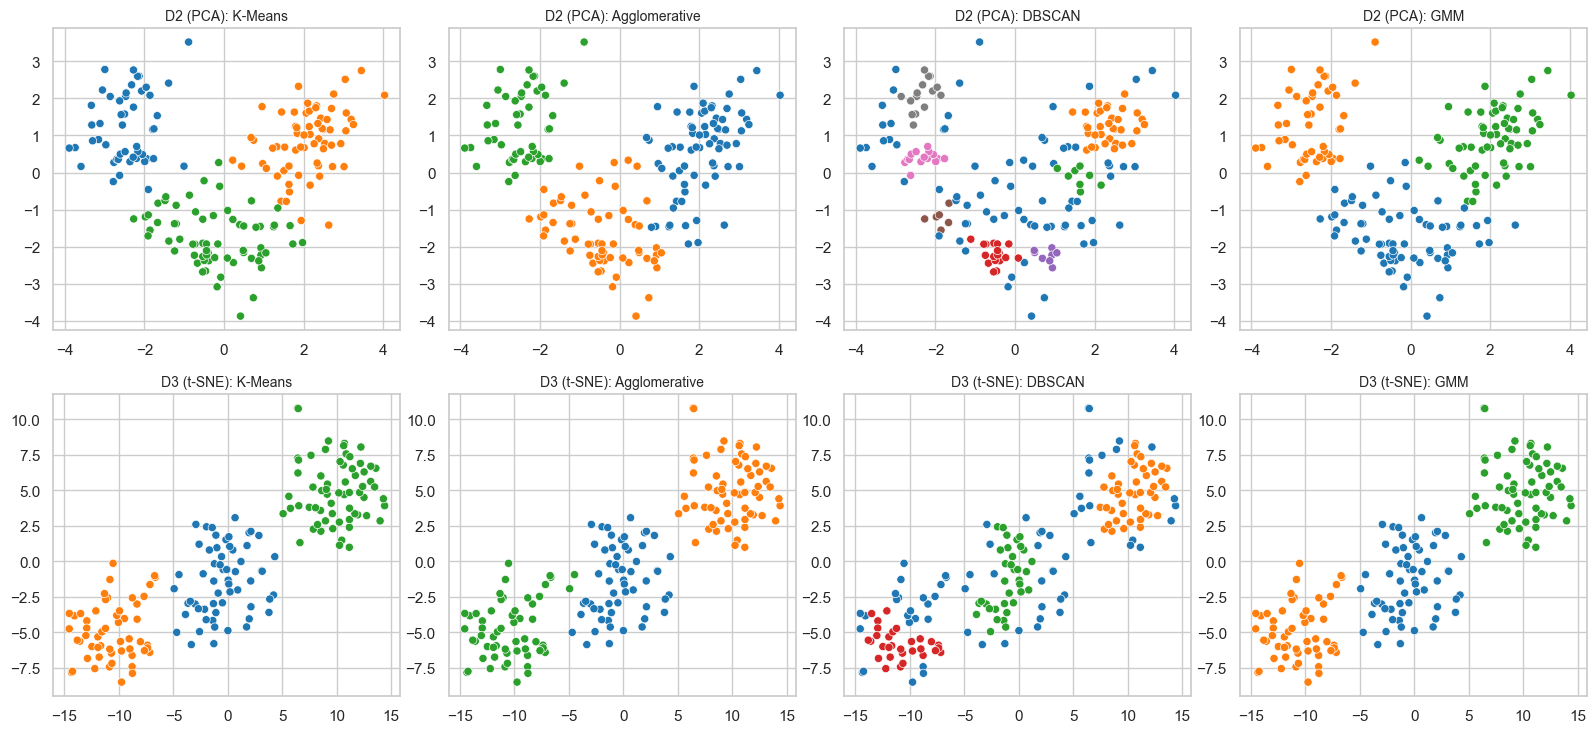

In [10]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7.5))
for r, sname in enumerate(("D2 (PCA)", "D3 (t-SNE)")):
    D = spaces[sname]
    for c, (mname, labels) in enumerate(labels_all[sname].items()):
        ax = axes[r, c]
        sns.scatterplot(x=D[:, 0], y=D[:, 1], hue=labels, palette="tab10", s=35, legend=False, ax=ax)
        ax.set_title(f"{sname}: {mname}", fontsize=10)
plt.tight_layout()
plt.show()

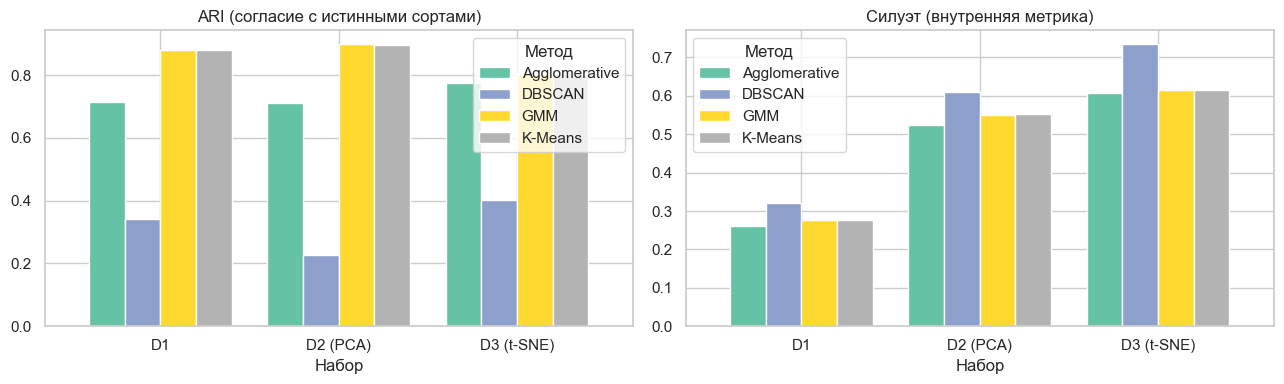

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
results["ARI"].unstack().loc[list(spaces)].plot(kind="bar", rot=0, ax=axes[0], colormap="Set2", width=0.8)
axes[0].set_title("ARI (согласие с истинными сортами)")
results["Силуэт"].unstack().loc[list(spaces)].plot(kind="bar", rot=0, ax=axes[1], colormap="Set2", width=0.8)
axes[1].set_title("Силуэт (внутренняя метрика)")
plt.tight_layout()
plt.show()

In [12]:
best_ari = results["ARI"].groupby(level="Набор").idxmax().map(lambda i: i[1])
best_sil = results["Силуэт"].groupby(level="Набор").idxmax().map(lambda i: i[1])
pd.DataFrame({"Лучший по ARI": best_ari, "Лучший по силуэту": best_sil}).loc[list(spaces)]

,Лучший по ARI,Лучший по силуэту
Набор,,
D1,K-Means,DBSCAN
D2 (PCA),GMM,DBSCAN
D3 (t-SNE),K-Means,DBSCAN


## 7. Выводы

- Для D1 из 13 признаков отобрано 12 (без использования метки исключён `Flavanoids`, сильно коррелирующий с другими признаками); признаки стандартизованы.
  D2 получен PCA (2 компоненты, 53 % дисперсии), D3 — t-SNE (perplexity = 30).
- На плоскости D3 три сорта образуют отдельные группы, на D2 сорта 1 и 2 частично перекрываются; по силуэту истинных меток t-SNE чуть чётче PCA (0.550 против 0.522).
- По согласию с истинными сортами (ARI) лучшими оказались: на D1 — K-Means и GMM (ARI 0.880, разбиения совпали), на D2 — GMM (0.898) и K-Means (0.895),
  на D3 — K-Means и GMM (0.802). Разница между K-Means и GMM на D2 (три тысячных ARI) несущественна. Эти методы подходят, потому что после стандартизации
  сорта образуют компактные облака, близкие к эллипсоидам, а число кластеров (3) удалось выбрать без меток по максимуму силуэта.
- Иерархическая кластеризация (Ward) хуже: ARI 0.714 на D1, 0.711 на D2 и 0.774 на D3. Вероятнее всего, жадное слияние кластеров ошибается на границе между сортами.
- DBSCAN имеет самый высокий силуэт на всех наборах (0.320, 0.609, 0.734), но худшие внешние метрики (ARI 0.343, 0.228, 0.404). Причина в том, что
  `eps`, подобранный по силуэту, даёт плотные ядра и относит к шуму 52, 74 и 69 точек из 178 (29–42 %); силуэт при этом считается без шума,
  а внешние метрики шум учитывают как отдельную группу. Поэтому «лучший по силуэту» здесь не означает лучший: метрики нельзя сравнивать без учёта шума.
- На D3 (t-SNE) K-Means и GMM работают хуже, чем на D2 (ARI 0.802 против 0.895), хотя визуально D3 разделён чётче: t-SNE искажает форму и размеры групп.
  Значения силуэта на разных наборах сравнивать между собой нельзя, так как это разные пространства.
- Выборка мала (178 образцов), поэтому различия в несколько сотых ARI следует считать несущественными; различия между группами методов (K-Means/GMM, Ward, DBSCAN) — существенны.